# Setup

In [1]:
import pandas as pd

df = pd.read_csv("riftbound_all_price_history.csv")

In [2]:
# Start with the table's dimensions and a few rows so we can understand the unit of observation.
# This helps reveal whether each row represents a card, a price observation, or another entity.
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
display(df.head())



Rows: 457,039 | Columns: 12


,date,product_id,name,set,number,printing,market_price_usd,url,snapshot_date,low,market,tickerMint_url
0,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-08-29,349.99,NaN,https://tickermint.cards/card/712806
1,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-08-30,349.99,NaN,https://tickermint.cards/card/712806
2,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-08-31,349.92,NaN,https://tickermint.cards/card/712806
3,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-09-01,349.92,NaN,https://tickermint.cards/card/712806
4,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-09-02,349.99,NaN,https://tickermint.cards/card/712806


In [3]:
# Inspect column types and non-null counts before choosing cleaning or analysis steps.
# Types can expose values that were loaded as text even though they should be numeric or dates.
df.info()

# Summarize missingness; percentages make it easier to prioritize columns with substantial gaps.
missing = df.isna().sum().to_frame("missing_count")
missing["missing_percent"] = (missing["missing_count"] / len(df) * 100).round(2)
display(missing.loc[missing["missing_count"] > 0].sort_values("missing_percent", ascending=False))

# Exact duplicate rows may indicate repeated observations or an upstream data issue.
print(f"Exact duplicate rows: {df.duplicated().sum():,}")



<class 'pandas.DataFrame'>
RangeIndex: 457039 entries, 0 to 457038
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   date              450922 non-null  str    
 1   product_id        457039 non-null  int64  
 2   name              457039 non-null  str    
 3   set               457039 non-null  str    
 4   number            443336 non-null  str    
 5   printing          457039 non-null  str    
 6   market_price_usd  450922 non-null  float64
 7   url               457039 non-null  str    
 8   snapshot_date     457039 non-null  str    
 9   low               457039 non-null  float64
 10  market            438907 non-null  float64
 11  tickerMint_url    457039 non-null  str    
dtypes: float64(3), int64(1), str(8)
memory usage: 41.8 MB


,missing_count,missing_percent
market,18132,3.97
number,13703,3.00
date,6117,1.34
market_price_usd,6117,1.34


Exact duplicate rows: 0


In [4]:
# Check what the difference is between data and snapshot_date
df[['product_id','name','date', 'snapshot_date']]

,product_id,name,date,snapshot_date
0,712806,Legacy - Booster Display,NaN,2026-08-29
1,712806,Legacy - Booster Display,NaN,2026-08-30
2,712806,Legacy - Booster Display,NaN,2026-08-31
3,712806,Legacy - Booster Display,NaN,2026-09-01
4,712806,Legacy - Booster Display,NaN,2026-09-02
...,...,...,...,...
457034,672088,Aspirant's Climb,2026-10-11,2026-10-07
457035,672088,Aspirant's Climb,2026-10-11,2026-10-08
457036,672088,Aspirant's Climb,2026-10-11,2026-10-09
457037,672088,Aspirant's Climb,2026-10-11,2026-10-10


In [5]:
#Looks like date is the day the dataset was downloaded
#From this I know we can drop date and the url columns as they will not be releveant to the market analysis
df['date'].unique()

<StringArray>
[nan, '2026-10-11']
Length: 2, dtype: str

In [6]:
print(df['market_price_usd'].equals(df['market']))


False


In [7]:
# Number of distinct prices each product_id has taken
n_prices = df.groupby('product_id')['market_price_usd'].nunique()

print(n_prices.value_counts().sort_index())          # how many cards have 1, 2, 3... distinct prices
print("Cards with a constant price:", (n_prices == 1).sum(), "of", len(n_prices))
print("Share constant:", (n_prices == 1).mean())

market_price_usd
0      92
1    1501
Name: count, dtype: int64
Cards with a constant price: 1501 of 1593
Share constant: 0.9422473320778405


In [8]:
# Number of distinct prices each product_id has taken
n_prices = df.groupby('product_id')['market'].nunique()

print(n_prices.value_counts().sort_index())          # how many cards have 1, 2, 3... distinct prices
print("Cards with a constant price:", (n_prices == 1).sum(), "of", len(n_prices))
print("Share constant:", (n_prices == 1).mean())

market
0      61
1      22
2      17
3      10
4       8
       ..
392     1
406     1
439     1
442     1
452     1
Name: count, Length: 291, dtype: int64
Cards with a constant price: 22 of 1593
Share constant: 0.013810420590081607


In [9]:
# Drop unnecessary columns and rows with missing market prices
# Change the data types of certain columns so they are more accurate
# Dropping NaN values is appropriate here since the focus is on pricing movement.
df_cleaned = df[df['market_price_usd'].notna()].drop(columns=['date', 'url', 'tickerMint_url', 'market_price_usd']).dropna()

df_cleaned['product_id'] = df_cleaned['product_id'].astype(int)
df_cleaned['snapshot_date'] = pd.to_datetime(df_cleaned['snapshot_date'])
df_cleaned.head()

,product_id,name,set,number,printing,snapshot_date,low,market
758,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-09-28,1100.00,617.5
759,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-09-29,1098.71,617.5
760,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-09-30,1098.71,617.5
761,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-10-01,999.99,617.5
762,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-10-02,999.99,617.5


# Since the dataset combines both sealed and singles I believe it is important to seperate the 2 in distinct datasets

In [10]:
singles = df_cleaned[df_cleaned['number'].notna()]
singles.head()

,product_id,name,set,number,printing,snapshot_date,low,market
758,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-09-28,1100.00,617.5
759,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-09-29,1098.71,617.5
760,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-09-30,1098.71,617.5
761,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-10-01,999.99,617.5
762,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-10-02,999.99,617.5


In [11]:
sealed = df_cleaned[df_cleaned['number'].isna()]
sealed.head()

,product_id,name,set,number,printing,snapshot_date,low,market


# Singles Data Cleaning & Exploration
### Start with this to try to spot any trends

In [12]:
singles 

,product_id,name,set,number,printing,snapshot_date,low,market
758,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-09-28,1100.00,617.50
759,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-09-29,1098.71,617.50
760,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-09-30,1098.71,617.50
761,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-10-01,999.99,617.50
762,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,2026-10-02,999.99,617.50
...,...,...,...,...,...,...,...,...
457034,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,2026-10-07,30.00,43.57
457035,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,2026-10-08,30.00,42.77
457036,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,2026-10-09,30.00,41.83
457037,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,2026-10-10,30.00,41.83


In [13]:
singles.groupby('product_id')['market'].mean()

product_id
652771       0.170261
652772       0.136373
652773       0.112832
652774       0.287827
652775       0.181522
             ...     
716021    1498.000000
716026    1300.000000
716035    1333.907586
721767       0.087500
721871     300.000000
Name: market, Length: 1439, dtype: float64

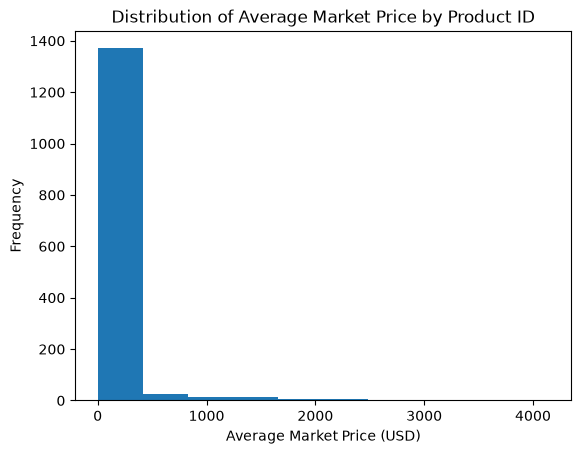

In [14]:
import matplotlib.pyplot as plt

singles.groupby('product_id')['market'].mean().plot(kind='hist', bins = 10)
plt.xlabel('Average Market Price (USD)')
plt.ylabel('Frequency')
plt.title('Distribution of Average Market Price by Product ID')
plt.show()

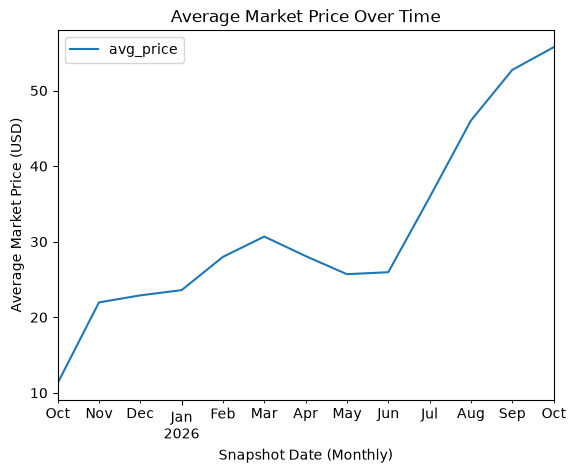

In [15]:
monthly = singles.groupby(
    singles['snapshot_date'].dt.to_period('M')
).agg(
    avg_price=('market', 'mean'),
    card_count=('market', 'count')
)

monthly.plot(y='avg_price', kind='line')
plt.xlabel('Snapshot Date (Monthly)')
plt.ylabel('Average Market Price (USD)')
plt.title('Average Market Price Over Time')
plt.show()

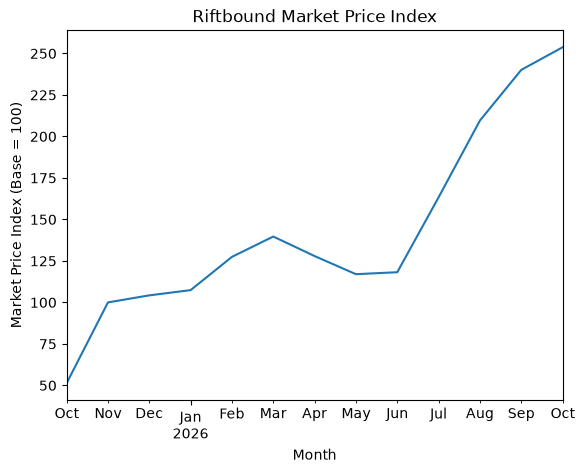

In [16]:
monthly['price_index'] = (
    monthly['avg_price'] / monthly['avg_price'].iloc[1]
) * 100

monthly['price_index'].plot(kind='line')

plt.xlabel('Month')
plt.ylabel('Market Price Index (Base = 100)')
plt.title('Riftbound Market Price Index')
plt.show()

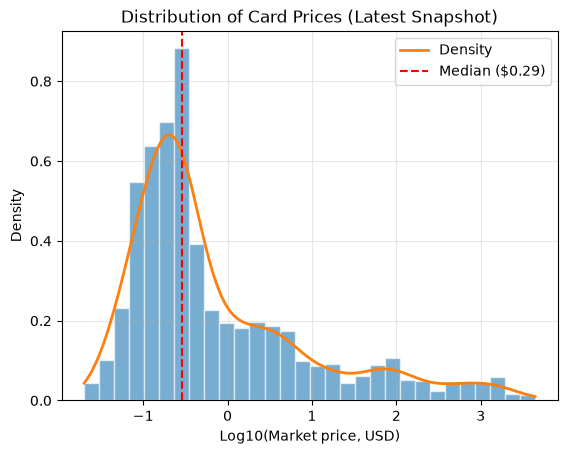

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

latest = singles[singles['snapshot_date'] == singles['snapshot_date'].max()]
prices = latest['market']
log_data = np.log10(prices[prices > 0].dropna())   # log10(0) = -inf breaks the plot

# Histogram as density so the line is on the same scale
plt.hist(log_data, bins=30, density=True, alpha=0.6, edgecolor="white")

# Smooth density line (KDE)
x = np.linspace(log_data.min(), log_data.max(), 300)
plt.plot(x, gaussian_kde(log_data)(x), linewidth=2, label="Density")

# Optional: vertical median line
plt.axvline(log_data.median(), color="red", linestyle="--", label=f"Median (${10**log_data.median():.2f})")

plt.xlabel("Log10(Market price, USD)")
plt.ylabel("Density")
plt.title("Distribution of Card Prices (Latest Snapshot)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [18]:
latest = singles[singles['snapshot_date'] == singles['snapshot_date'].max()]
p = latest['market'].dropna()
p = p[p > 0]

print(p.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]))
print("Mean / median:", p.mean() / p.median())

# Share of total market value held by the top cards
s = p.sort_values(ascending=False)
for k in [10, 25, 50]:
    print(f"Top {k} cards = {s.head(k).sum() / s.sum():.1%} of total value")

count    1948.000000
mean       58.300175
std       295.409607
min         0.020000
10%         0.080000
25%         0.140000
50%         0.290000
75%         2.120000
90%        45.742000
95%       175.297500
99%      1499.049400
max      4400.000000
Name: market, dtype: float64
Mean / median: 201.0350846137506
Top 10 cards = 26.8% of total value
Top 25 cards = 47.8% of total value
Top 50 cards = 72.0% of total value


tier
bulk (<$0.30)    994
$0.30-1          351
$1-5             257
$5-25            125
$25+             221
Name: count, dtype: int64


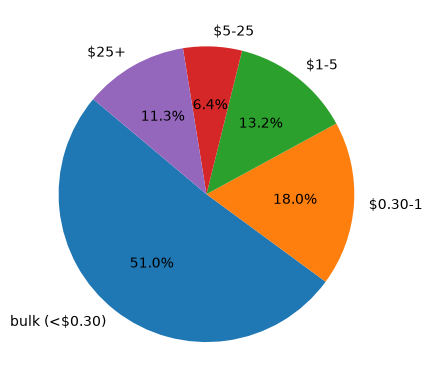

In [19]:
bins   = [0, 0.30, 1, 5, 25, np.inf]
labels = ["bulk (<$0.30)", "$0.30-1", "$1-5", "$5-25", "$25+"]
latest = latest.assign(tier=pd.cut(latest['market'], bins=bins, labels=labels))
print(latest['tier'].value_counts().sort_index())
tier_counts = latest['tier'].value_counts().sort_index()
plt.pie(tier_counts, labels=tier_counts.index, autopct='%1.1f%%', startangle=140)
plt.show()

In [20]:
piv = singles.pivot_table(index='snapshot_date', columns='product_id',
                          values='market')
basket = piv.dropna(axis=1)                     # cards present on all dates
rel = basket / basket.iloc[0]                   # each card relative to day 1
index_equal = rel.median(axis=1) * 100          # robust "typical card" index
index_mean  = rel.mean(axis=1) * 100            # equal-weighted, mean

print(index_equal.tail())
print(index_mean.tail())


snapshot_date
2026-10-07    32.989691
2026-10-08    33.035714
2026-10-09    33.035714
2026-10-10    33.035714
2026-10-11    33.000000
dtype: float64
snapshot_date
2026-10-07    64.455144
2026-10-08    63.809663
2026-10-09    63.352251
2026-10-10    62.503380
2026-10-11    61.629559
dtype: float64


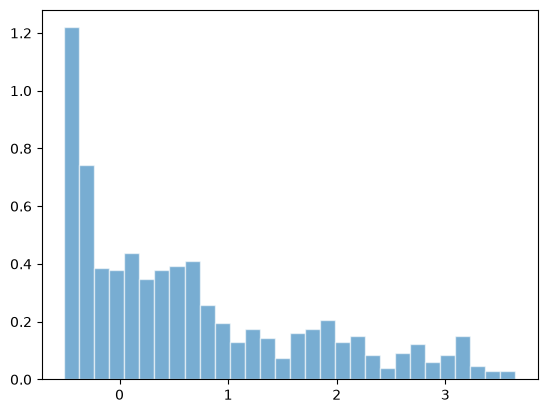

In [21]:
# If we remove the bulk I wonder what the distribution looks like
latest = singles[singles['snapshot_date'] == singles['snapshot_date'].max()]
prices = latest['market']
log_data = np.log10(prices[prices > 0.30].dropna())

plt.hist(log_data, bins=30, density=True, alpha=0.6, edgecolor="white")
plt.show()

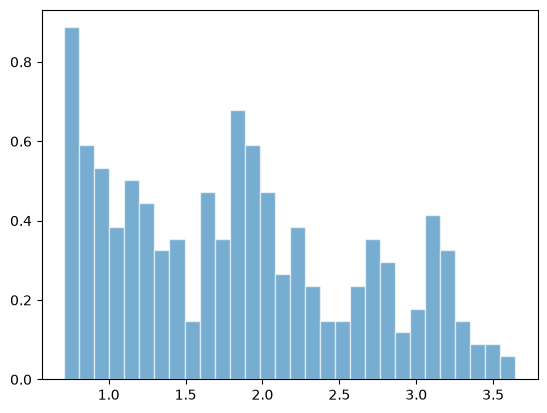

In [22]:
# If we keep the more expensive ones 
latest = singles[singles['snapshot_date'] == singles['snapshot_date'].max()]
prices = latest['market']
log_data = np.log10(prices[prices > 5].dropna())

plt.hist(log_data, bins=30, density=True, alpha=0.6, edgecolor="white")
plt.show()

In [23]:
# Correlation between snapshot_date and market price
# Convert dates to a numeric ordinal so Pearson correlation can be computed
corr_df = singles[['snapshot_date', 'market']].dropna().copy()
corr_df['date_num'] = corr_df['snapshot_date'].map(pd.Timestamp.toordinal)

overall = corr_df['date_num'].corr(corr_df['market'])
print(f"Overall Pearson r (date vs price): {overall:.3f}")

# Also Spearman for monotonic:

print("Overall Spearman rho:", corr_df['date_num'].corr(corr_df['market'], method='spearman'))

# Per-card correlation:

# Include product_id so observations can be grouped by card.
corr_df = singles[['product_id', 'snapshot_date', 'market']].dropna().copy()
corr_df['date_num'] = corr_df['snapshot_date'].map(pd.Timestamp.toordinal)

overall = corr_df['date_num'].corr(corr_df['market'])
print(f"Overall Pearson r (date vs price): {overall:.3f}")
print(
    "Overall Spearman rho:",
    corr_df['date_num'].corr(corr_df['market'], method='spearman')
)

# Per-card Pearson correlation; require at least 3 observations.
per_card = corr_df.groupby('product_id').apply(
    lambda g: g['date_num'].corr(g['market']) if len(g) > 2 else np.nan
)

display(per_card.describe())

# But singles has product_id. Compute per product correlation and summarize.

per_card = corr_df.groupby('product_id').apply(
    lambda g: g['date_num'].corr(g['market']) if len(g) > 2 else np.nan,
    include_groups=False
)



per_card = corr_df.groupby('product_id')[['date_num','market']].apply(
    lambda g: g['date_num'].corr(g['market'])
)

Overall Pearson r (date vs price): 0.048
Overall Spearman rho: -0.09571123840755828
Overall Pearson r (date vs price): 0.048
Overall Spearman rho: -0.09571123840755828


count    1431.000000
mean       -0.244732
std         0.433915
min        -0.993269
25%        -0.527807
50%        -0.326114
75%        -0.064033
max         0.995107
dtype: float64

In [24]:
singles = singles.sort_values(['product_id', 'snapshot_date'])

singles['previous_price'] = (
    singles.groupby('product_id')['market'].shift(1)
)

singles['price_change'] = (
    singles['market'] - singles['previous_price']
)

singles['pct_change'] = (
    singles['market'] / singles['previous_price'] - 1
)

singles['log_return'] = np.log(
    singles['market'] / singles['previous_price']
)

In [25]:
card_returns = singles.groupby('product_id').agg(
    first_price=('market', 'first'),
    latest_price=('market', 'last'),
    observations=('market', 'count')
)

card_returns['total_return'] = (
    card_returns['latest_price'] / card_returns['first_price'] - 1
)

card_returns = card_returns[card_returns['observations'] >= 3]

display(card_returns.sort_values('total_return', ascending=False).head(20))
display(card_returns.sort_values('total_return').head(20))

,first_price,latest_price,observations,total_return
product_id,,,,
707658,0.25,74.81,73,298.240000
666469,3.00,606.22,236,201.073333
666467,0.96,65.40,240,67.125000
662891,10.00,238.17,337,22.817000
706049,0.27,4.45,75,15.481481
706043,0.25,1.63,75,5.520000
662898,237.50,1430.38,336,5.022653
706103,0.25,1.45,75,4.800000
662886,10.00,56.08,337,4.608000


,first_price,latest_price,observations,total_return
product_id,,,,
663445,49.99,0.20,251,-0.995999
706089,25.00,0.14,88,-0.994400
684511,30.00,0.22,190,-0.992667
706036,9.99,0.10,83,-0.989990
666598,34.99,0.38,251,-0.989140
706120,9.99,0.11,78,-0.988989
684600,15.00,0.18,188,-0.988000
685487,30.00,0.39,200,-0.987000
684495,60.00,0.79,200,-0.986833


In [26]:
volatility = singles.groupby('product_id').agg(
    mean_price=('market', 'mean'),
    median_price=('market', 'median'),
    std_price=('market', 'std'),
    observations=('market', 'count')
)

volatility['cv'] = (
    volatility['std_price'] / volatility['mean_price']
)

volatility = volatility[volatility['observations'] >= 3]

display(volatility.sort_values('cv', ascending=False).head(20))

,mean_price,median_price,std_price,observations,cv
product_id,,,,,
663445,2.102510,0.240,8.737607,251,4.155798
666598,1.484661,0.300,5.805058,251,3.910022
664927,0.563755,0.160,1.779721,253,3.156905
706006,0.957975,0.080,2.837390,79,2.961863
685568,1.394699,0.340,4.041269,166,2.897593
684488,0.558855,0.160,1.600268,166,2.863475
665023,2.922948,0.860,8.345447,251,2.855147
706120,0.929615,0.140,2.640677,78,2.840612
665012,0.885040,0.340,2.484560,252,2.807286


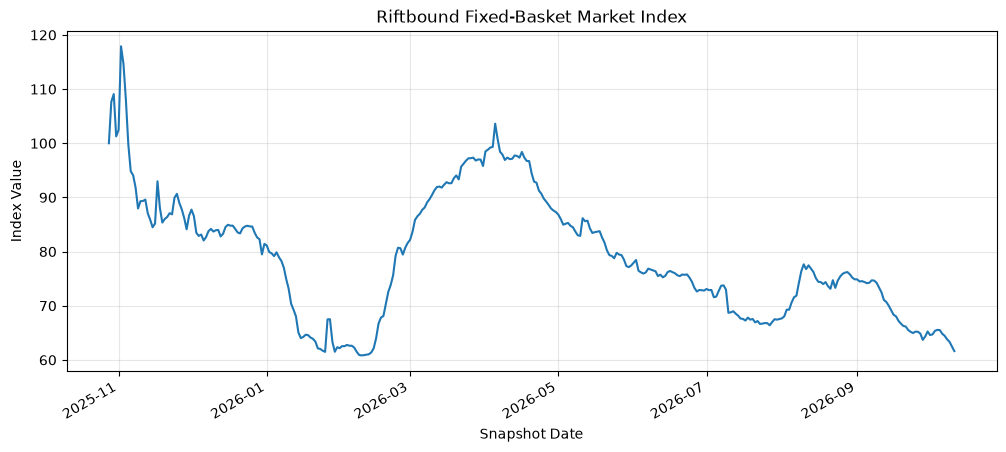

In [27]:
piv = singles.pivot_table(
    index='snapshot_date',
    columns='product_id',
    values='market',
    aggfunc='mean'
)

basket = piv.dropna(axis=1)

# Calculate relative price movement from the first observation
relative_prices = basket.div(basket.iloc[0])

# Equal-weighted market index
market_index = relative_prices.mean(axis=1) * 100

market_index.plot(figsize=(12, 5))

plt.ylabel('Index Value')
plt.xlabel('Snapshot Date')
plt.title('Riftbound Fixed-Basket Market Index')
plt.grid(alpha=0.3)
plt.show()